# K-MEANS

- Un algoritmo de aprendizaje no supervisado de la categoría: **métodos particionales**.
- Un cluster se resume mediante un prototipo

--------

## ¿Cómo funciona?

1. Inicializa K centroides (uno para cada cluster)
$$
c_k = \frac{1}{C_k} \sum_{x^{(i)} \in C_k } x^{(i)} 
$$

2. Le asigna el cluster más cercano a cada punto

$$
z^{(i)} = \text{arg mín}_k || x^{(i)} - c_k ||_2^2
$$

3. En cada cluster, calcula las medias de sus puntos para actualizar el centroide

$$
c_k = \frac{1}{|c_k|} \sum_{x^{(i)} \in C_k } x^{(i)} 
$$

4. Si aún no converge (maximo de iteraciones o cuando las particiones dejan de cambiar), pasar a 2

-------

## ¿Por qué k-means?

- K es un hiperparámetro que definimos nosotros. Depende del problema y las necesidades del negocio / cliente.
- Means porque el centroide es el promedio de sus instancias
- Podemos usar el método del codo para estimar cual es el "k ideal" si no sabemos cuántas k definir de antemano

### SSE (Sum of Squared Errors)

Como su criterio de optimización, el algoritmo alterna asignación y actualización buscando reducir la **SSE**:

$$
J_{KM} = \sum_{k=1}^{K} \sum_{x^{(i)} \in C_k} \lVert x^{(i)} - c_k \rVert_2^2
$$

- También se le conoce como **inercia** (*inertia*)
- El procedimiento converge en un mínimo local, por ello la inicialización puede afectar la solución obtenida
- El centroide se define al inicio de manera aleatoria

------

# Implementación en código

- Usaremos la clase KMeans de Scikit-Learn
- Como es un algoritmo basado en instancias, es sensible si los datos están en diferentes escalas (ej. tener millones en una característica y decenas en otra).
    - Por lo que usaremos MinMaxScaler para escalar cada dato:
    $$
    X_i^{*} = \frac{X_i - min(X)}{max(X) - min(X)}
    $$

- Como se había dicho, los centroides se definen al inicio de manera aleatoria, para reproducibilidad, se usará 42 como random state

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
plt.style.use('dark_background') # poner modo oscuro los plots

RAND_STATE = 42
K = 3   

---------

## Nuestros datos

In [167]:
df = pd.DataFrame({
    "x_1":[0, 1, 0, 4, 6, 8, 10, 1, 1, 1,3 , 5],
    "x_2":[0, 0, 1, 0, 0, 1, 2, 5, 7, 9, 9, 9 ]
})

df

,x_1,x_2
0,0,0
1,1,0
2,0,1
3,4,0
4,6,0
5,8,1
6,10,2
7,1,5
8,1,7
9,1,9


--------

## Visualmente

Text(0, 0.5, 'x_2')

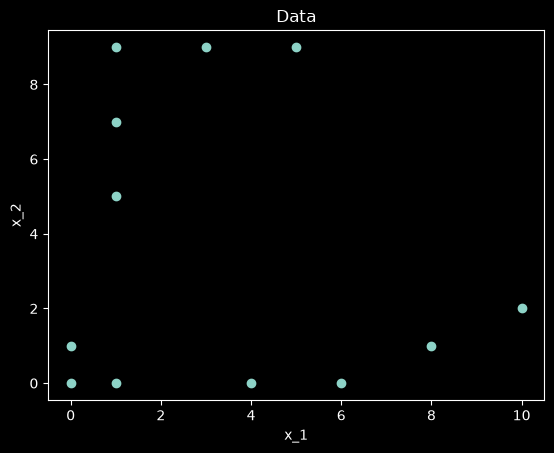

In [168]:
plt.scatter(df['x_1'], df['x_2'])
plt.title("Data")
plt.xlabel("x_1")
plt.ylabel("x_2")

-----------

### Escalamos nuestros datos

In [ ]:
escalador = MinMaxScaler().fit(df.values) # valores escalados

# guardar los valores escalados
df = pd.DataFrame(
    escalador.transform(df.values),
    columns=['x_1', 'x_2']
)

df

,x_1,x_2
0,0.0,0.000000
1,0.1,0.000000
2,0.0,0.111111
3,0.4,0.000000
4,0.6,0.000000
5,0.8,0.111111
6,1.0,0.222222
7,0.1,0.555556
8,0.1,0.777778
9,0.1,1.000000


---------


### Creación del modelo


In [ ]:
# generar el modelo
model = KMeans(n_clusters=K, random_state=RAND_STATE).fit(df.values)

# ver los clusters (0, 1, 2, ...) de cada uno de los datos
model.labels_

array([2, 2, 2, 0, 0, 0, 0, 1, 1, 1, 1, 1], dtype=int32)

In [178]:
# agregar columna de la etiqueta de cluster al df
df['cluster'] = model.labels_

df.head()

,x_1,x_2,cluster
0,0.0,0.000000,2
1,0.1,0.000000,2
2,0.0,0.111111,2
3,0.4,0.000000,8
4,0.6,0.000000,1


---------

### Cosas Importantes

- La inercia (SSE) se calcula con la distancia al cuadrado de cada uno de los puntos hacia el centroide. Al ^2 porque le da más importancia a los puntos que se encuentran más lejos y menor importancia a los puntos que se encuentran muy cerca. Suma todas las distancias y las pondera por el número de instancias que se tienen para un cluster dado

- las metricas siempre deben de estar asociadas al negocio, no siempre que sea mejor es bueno significa que la inercia sea baja

- lo deseable es tener un valor k bajo y un valor de inercia pequeño

In [ ]:
print(model.n_clusters)

# ver dónde se ubicaron los centroides:
print('\n',model.cluster_centers_)

# qué tan bien conformados están nuestros clusters
print('\n', model.inertia_) # que tan pegados están los puntos entre si (segun su cluster)


3

 [[0.7        0.08333333]
 [0.22       0.86666667]
 [0.03333333 0.03703704]]

 0.5348724279835391


---------

### Viendo los clusters

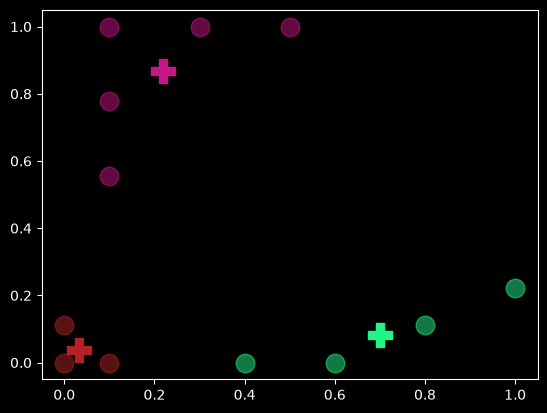

In [174]:
# graficar

colors = ['#22F588','#C71585','#B22222']

for cluster in range(model.n_clusters):
    plt.scatter(
        df[df['cluster'] == cluster]['x_1'],
        df[df['cluster'] == cluster]['x_2'],
        marker='o',
        s=180,
        color=colors[cluster],
        alpha=0.5
    )

    plt.scatter(model.cluster_centers_[cluster][0],
                model.cluster_centers_[cluster][1],
                marker='P', s=280, color=colors[cluster])

------


## Método del codo

- Para encontrar el numero "ideal" de clusters, se puede usar el método del codo.
- Simplemente visualmente escogemos del "brazo formado por el grafico de las inercias". 
- El "codo" es el punto dónde hay mayor cambio de inercia.
- La "desventaja" es que puede ser un poco ambiguo porque el k inicial podría ser uno a la derecha o una a la izquierda
- Además, el número de clusters (K) depende más del problema y las necesidades del negocio

In [175]:
inercias = []

# calcular las inercias para cada 'k'
x = range(2, 10)
for k in x:
    model = KMeans(n_clusters=k).fit(df.values)
    inercias.append(model.inertia_)

print(inercias)

[3.765740740740741, 0.534872427983539, 0.38915226337448566, 0.16576131687242796, 0.1410699588477366, 0.11489711934156381, 0.0948971193415638, 0.034897119341563795]


-------

Text(0, 0.5, 'inercias')

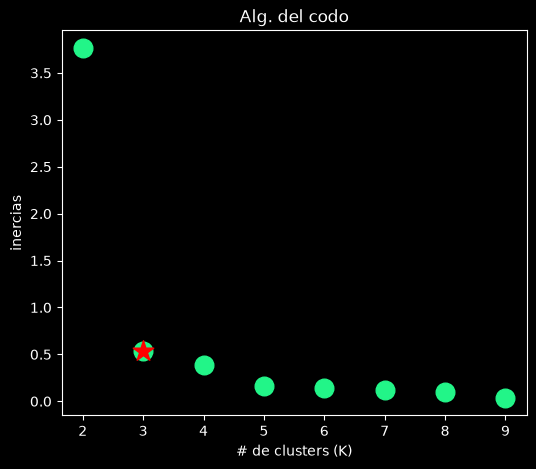

In [ ]:
plt.figure(figsize=(6, 5), dpi=100)
plt.title("Alg. del codo")
plt.scatter(
    x,
    inercias,
    s=180,
    color="#22F588"
)

# destacar al mejor k
plt.scatter(x[1], inercias[1], marker='*', s=240, color="red")

plt.xlabel("# de clusters (K)")
plt.ylabel("inercias")

---------

### Referencias:

- https://www.youtube.com/watch?v=mICySHB0fh4
- Hands-on Machine Learning with Scikit-Learn, Keras & TensorFlow. Chapter 9: Unsupervised Learning Techniques